# Projet 2

In [3]:
import os, re
from glob import glob as ls
from PIL import Image, ImageDraw
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd
import seaborn as sns; sns.set()
import qgrid
from PIL import Image
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings("ignore")
from sys import path
from intro_science_donnees import *
from intro_science_donnees import data
from utilities import *


In [4]:
dataset_dir = 'data/512x512/'
images = load_images(dataset_dir, "*.jpg")

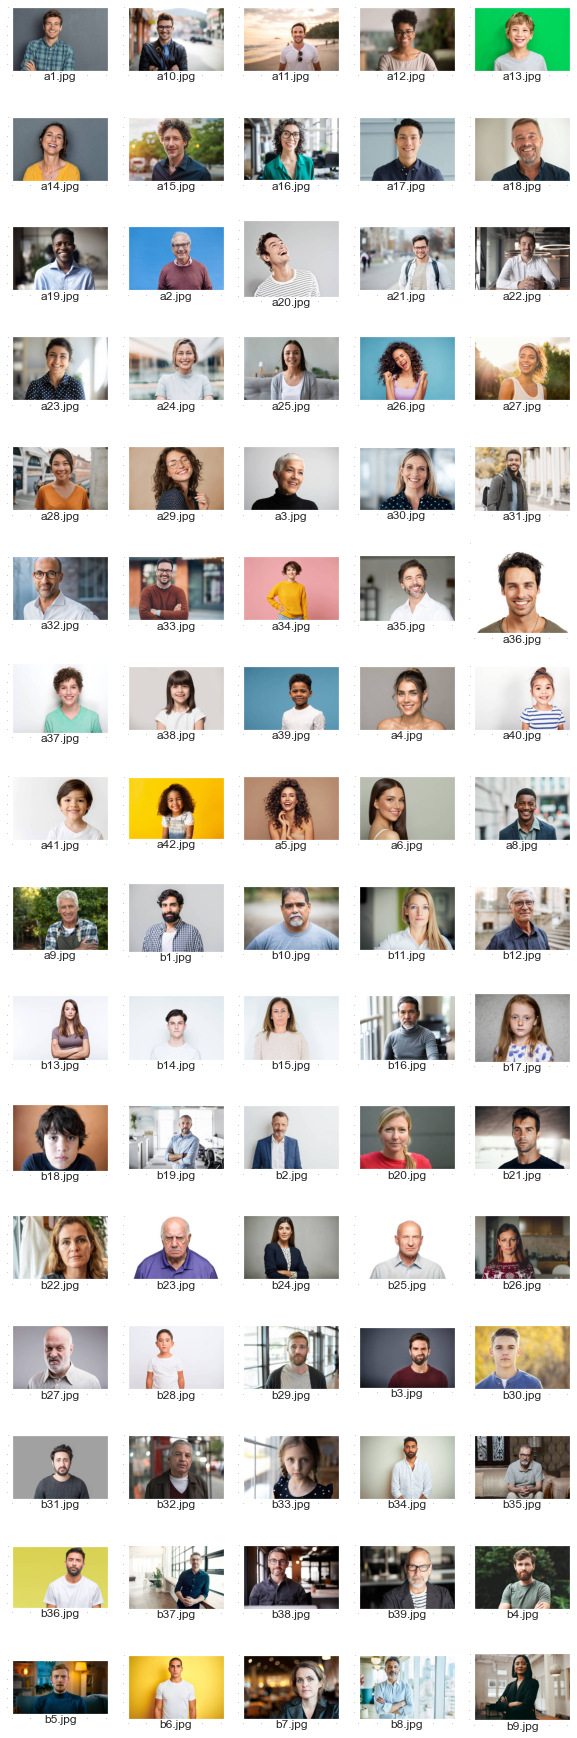

In [5]:
image_grid(images, titles=images.index)

In [6]:
images

a1.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
a10.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
a11.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
a12.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
a13.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
                                 ...                        
b5.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b6.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b7.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b8.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b9.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
Length: 80, dtype: object

In [7]:
type(images)

pandas.core.series.Series

In [8]:
images.index

Index(['a1.jpg', 'a10.jpg', 'a11.jpg', 'a12.jpg', 'a13.jpg', 'a14.jpg',
       'a15.jpg', 'a16.jpg', 'a17.jpg', 'a18.jpg', 'a19.jpg', 'a2.jpg',
       'a20.jpg', 'a21.jpg', 'a22.jpg', 'a23.jpg', 'a24.jpg', 'a25.jpg',
       'a26.jpg', 'a27.jpg', 'a28.jpg', 'a29.jpg', 'a3.jpg', 'a30.jpg',
       'a31.jpg', 'a32.jpg', 'a33.jpg', 'a34.jpg', 'a35.jpg', 'a36.jpg',
       'a37.jpg', 'a38.jpg', 'a39.jpg', 'a4.jpg', 'a40.jpg', 'a41.jpg',
       'a42.jpg', 'a5.jpg', 'a6.jpg', 'a8.jpg', 'a9.jpg', 'b1.jpg', 'b10.jpg',
       'b11.jpg', 'b12.jpg', 'b13.jpg', 'b14.jpg', 'b15.jpg', 'b16.jpg',
       'b17.jpg', 'b18.jpg', 'b19.jpg', 'b2.jpg', 'b20.jpg', 'b21.jpg',
       'b22.jpg', 'b23.jpg', 'b24.jpg', 'b25.jpg', 'b26.jpg', 'b27.jpg',
       'b28.jpg', 'b29.jpg', 'b3.jpg', 'b30.jpg', 'b31.jpg', 'b32.jpg',
       'b33.jpg', 'b34.jpg', 'b35.jpg', 'b36.jpg', 'b37.jpg', 'b38.jpg',
       'b39.jpg', 'b4.jpg', 'b5.jpg', 'b6.jpg', 'b7.jpg', 'b8.jpg', 'b9.jpg'],
      dtype='object')

In [9]:
d = {"Class": [1 if s[0] == 'a' else -1 for s in images.index]
}

In [10]:
data = pd.DataFrame(data=d, index=images.index)
data

,Class
a1.jpg,1
a10.jpg,1
a11.jpg,1
a12.jpg,1
a13.jpg,1
...,...
b5.jpg,-1
b6.jpg,-1
b7.jpg,-1
b8.jpg,-1


In [11]:
def calc_seuil(img : Image.Image) -> int:
    n = np.array(img)
    G = np.min(n[:, :, 0:3], axis=2)
    return((np.mean(G) + np.std(G))/2)

def invert(n : np.ndarray, force : bool = False) -> np.ndarray:
    G = n.mean()
    return np.invert(n) if force or G > 0.5 else n


img = images[6]
image_grid([invert(foreground_filter(img, calc_seuil(img))), invert(foreground_filter(img, calc_seuil(img)))])
print(np.argwhere(invert(foreground_filter(img, calc_seuil(img)))))

[[  0   0]
 [  0   1]
 [  0   2]
 ...
 [339 121]
 [339 122]
 [339 123]]


In [12]:
img_foreground = np.array([invert(foreground_filter(img, calc_seuil(img))) for img in images])

In [13]:
img_foreground

array([array([[False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
              ...,
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False]]),
       array([[ True,  True,  True, ...,  True,  True,  True],
              [ True,  True,  True, ...,  True,  True,  True],
              [ True,  True,  True, ...,  True,  True,  True],
              ...,
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False]]),
       array([[False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
             

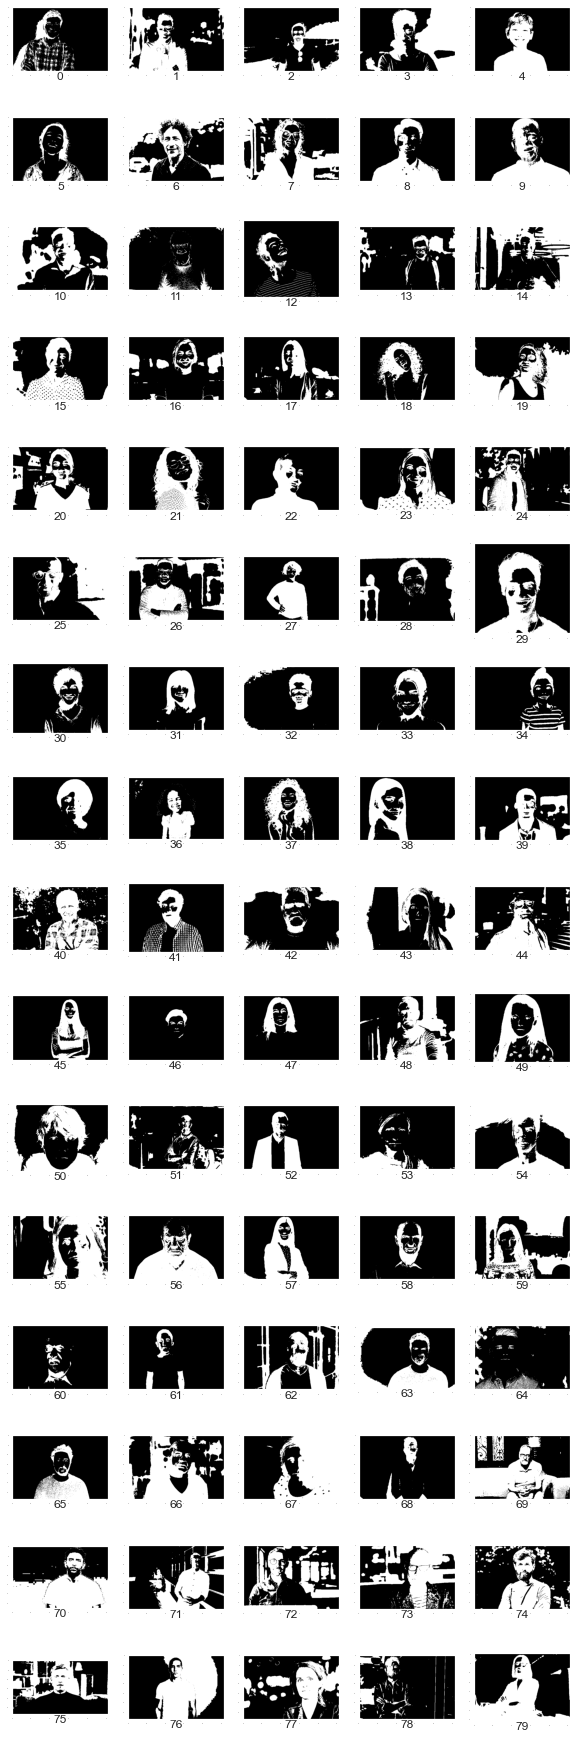

In [14]:
image_grid(img_foreground)

In [15]:
img_barycentre = np.array([place_barycentre(img) for img in img_foreground])

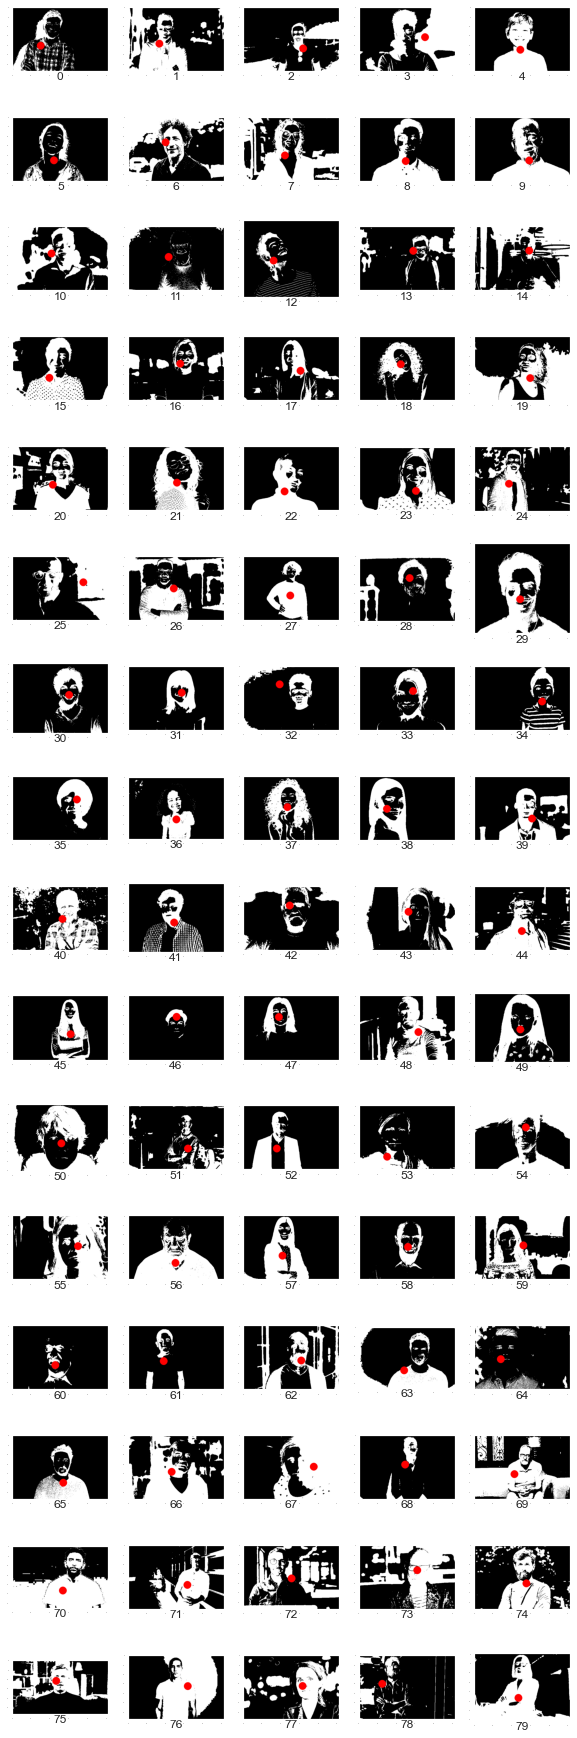

In [16]:
image_grid(img_barycentre)

In [17]:
img_barycentre

array([<PIL.Image.Image image mode=RGB size=512x340 at 0x7EFD4F574910>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7EFD4FA63220>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7EFD4FA63280>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7EFD4FA63040>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7EFD4FA63310>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7EFD4F1C9610>,
       <PIL.Image.Image image mode=RGB size=512x340 at 0x7EFD4F53C9D0>,
       <PIL.Image.Image image mode=RGB size=512x337 at 0x7EFD4F201D60>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7EFD4F218100>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7EFD4F40D0A0>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7EFD4F2D5AC0>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7EFD4F3AD5B0>,
       <PIL.Image.Image image mode=RGB size=512x410 at 0x7EFD4F3F6310>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7EFD4F3

In [18]:
img_foreground[0].shape

(340, 512)

In [19]:
images_cropped = pd.Series([crop_around_barycentre(img_foreground[i], images[i]) for i in range(len(images))])
images_cropped.index = images.index

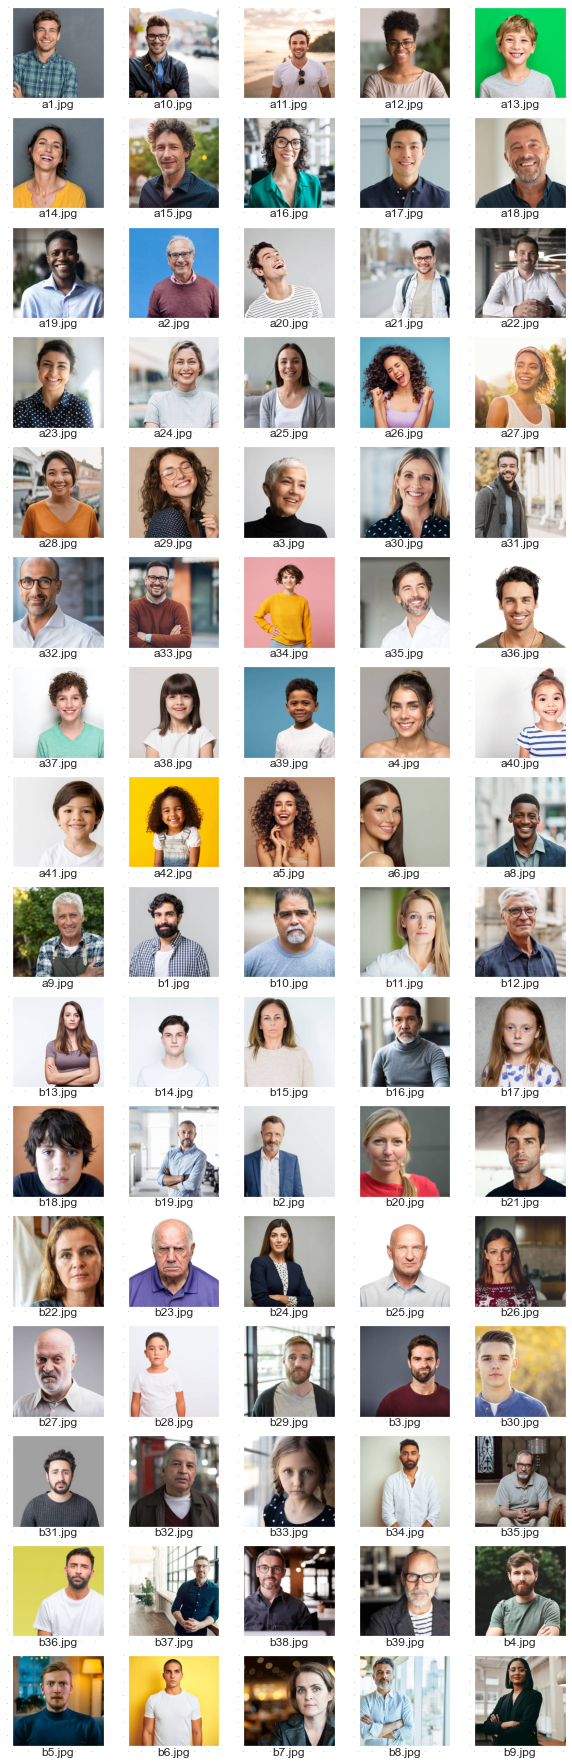

In [20]:
image_grid(images_cropped, titles=images_cropped.index)

In [21]:
images_resize = pd.Series([img.resize((64, 64)) for img in images_cropped])
images_resize.index = images.index

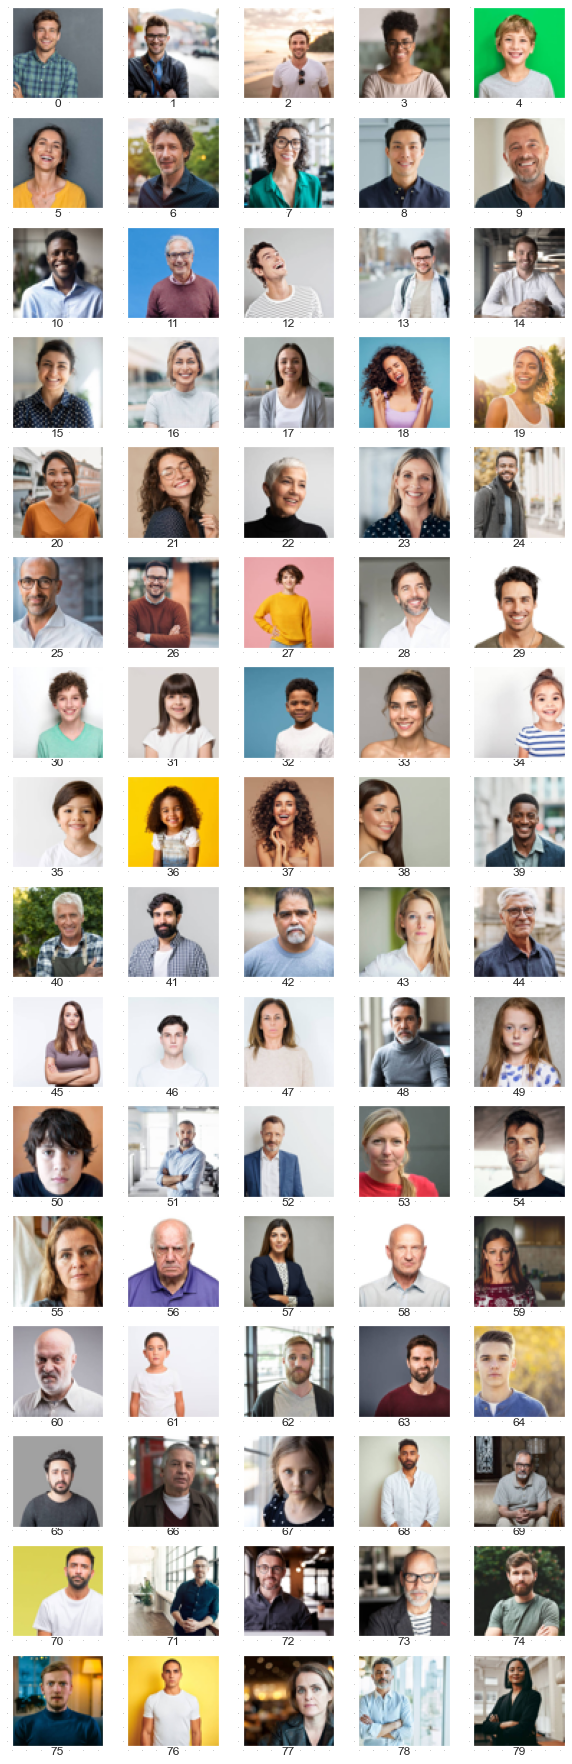

In [22]:
image_grid(images_resize)

In [23]:
print(np.array([images_cropped]))

[[<PIL.Image.Image image mode=RGB size=340x340 at 0x7EFD4D5AFFD0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4FAAEFA0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4D627100>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4D627940>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4D627DC0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4D627D60>
  <PIL.Image.Image image mode=RGB size=340x340 at 0x7EFD4D627850>
  <PIL.Image.Image image mode=RGB size=337x337 at 0x7EFD4D627C70>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4D627A90>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4D6275E0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4D6252B0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4D625280>
  <PIL.Image.Image image mode=RGB size=410x410 at 0x7EFD4D625970>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4D625130>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7EFD4D6D5070>
  <PIL.Ima

In [24]:
print(np.array(images_resize))

[<PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4BB5AB20>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4BB5AD90>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4BB5A730>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4BB5ACA0>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4D51A100>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4C331B50>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4BB5ABE0>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4BFB7A90>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4C316B20>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4C316AC0>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4C316A00>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4C3169D0>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4C316D00>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4C316BB0>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4C316AF0>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7EFD4C

In [25]:
#for i,img in enumerate(images_resize):
#    img.save("data/resize/"+images_resize.index[i])


In [26]:
foreground = pd.Series([invert(foreground_filter(img, 60)) for img in images_resize])

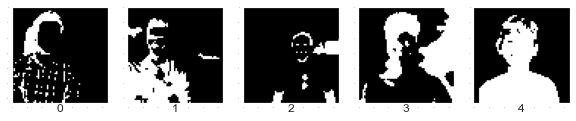

In [27]:
image_grid(foreground.head())

In [28]:
def color_correlation_filter(
    img: Union[Image.Image, np.ndarray], color: np.ndarray
) -> np.ndarray:
    """Return a grey-level image measuring the correlation of the pixels
    with the given color."""
    N = np.array(img, dtype='float64')
    r = np.array([[abs(np.corrcoef(linPix[i][0:3], color)[0, 1]) for i in range(len(linPix))] for linPix in N])
    return r

In [29]:
def color_fist_line(img : Image.Image) -> tuple:
    color = r, g, b = 0, 0, 0
    img_color = np.array(img)[:, 0, :]
    L = len(img_color)
    for l in img_color:
        r,g, b = (r+l[0], g+l[1], b+l[2])
    color = r, g, b = r/L, g/L, b/L
    return r,g, b

def color_fist_colonne(img : Image.Image) -> tuple:
    color = r, g, b = 0, 0, 0
    img_color = np.array(img)[0, :, :]
    L = len(img_color)
    for l in img_color:
        r,g, b = (r+l[0], g+l[1], b+l[2])
    color = r, g, b = r/L, g/L, b/L
    return r,g, b

def color_last_colonne(img : Image.Image) -> tuple:
    color = r, g, b = 0, 0, 0
    img_color = np.array(img)[-1, :, :]
    L = len(img_color)
    for l in img_color:
        r,g, b = (r+l[0], g+l[1], b+l[2])
    color = r, g, b = r/L, g/L, b/L
    return r,g, b

In [30]:
background = np.array([(color_correlation_filter(img, color_fist_line(img)) + color_correlation_filter(img, color_fist_colonne(img)) + color_correlation_filter(img, color_last_colonne(img))) for img in images_resize])

In [31]:
background2 = np.array([(color_correlation_filter(img, (0,0,255)) + color_correlation_filter(img, (0,255,0))) for img in images_resize])

In [32]:
moyennes = [background[i].mean for i in range(len(background))]

In [33]:
contour = np.array([contours(img) for img in images_resize])

In [73]:
def superieur_couleur(M : np.ndarray) -> np.ndarray:
    N = [[False for j in range(len(M))] for i in range(len(M))]


    for x, l in enumerate(M):
        for y, l2 in enumerate(l):
            r, g, b = l2 > 40
            N[x][y] = r and g and b
    return np.array(N)

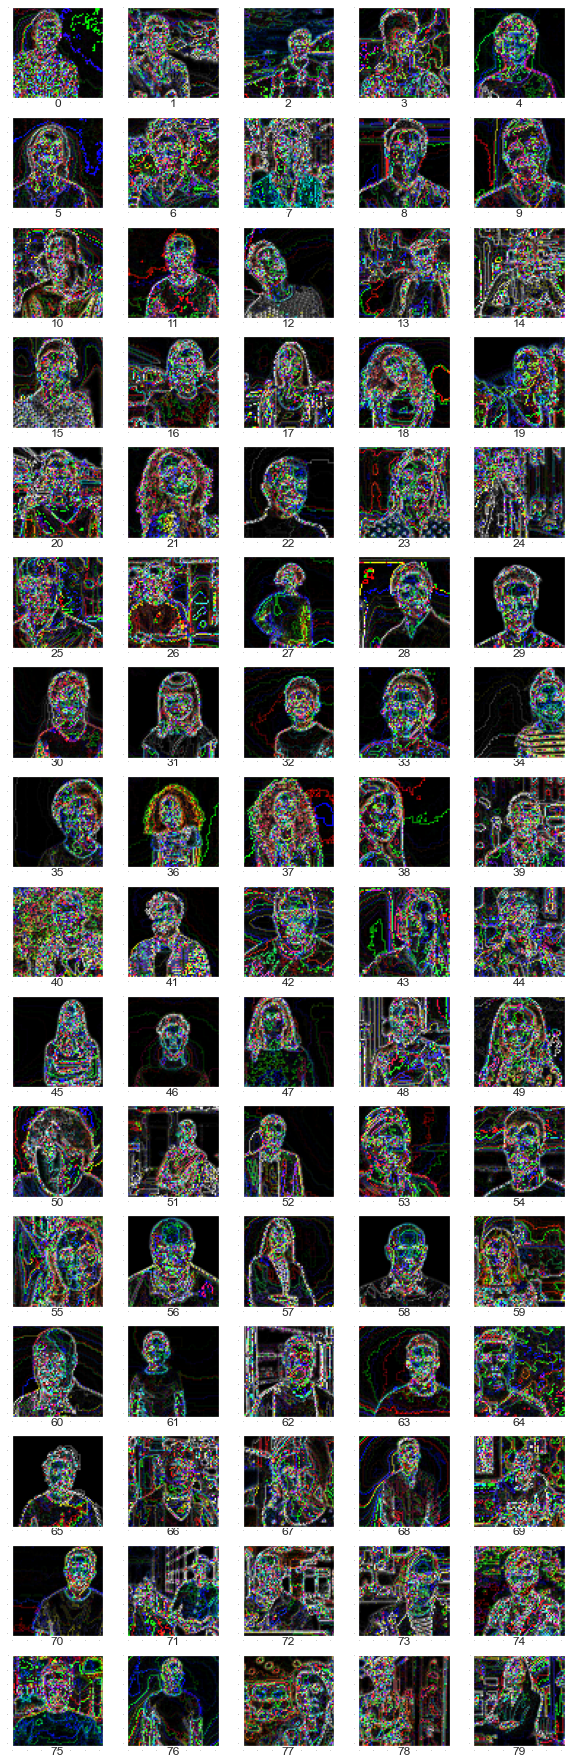

In [35]:
image_grid(contour)

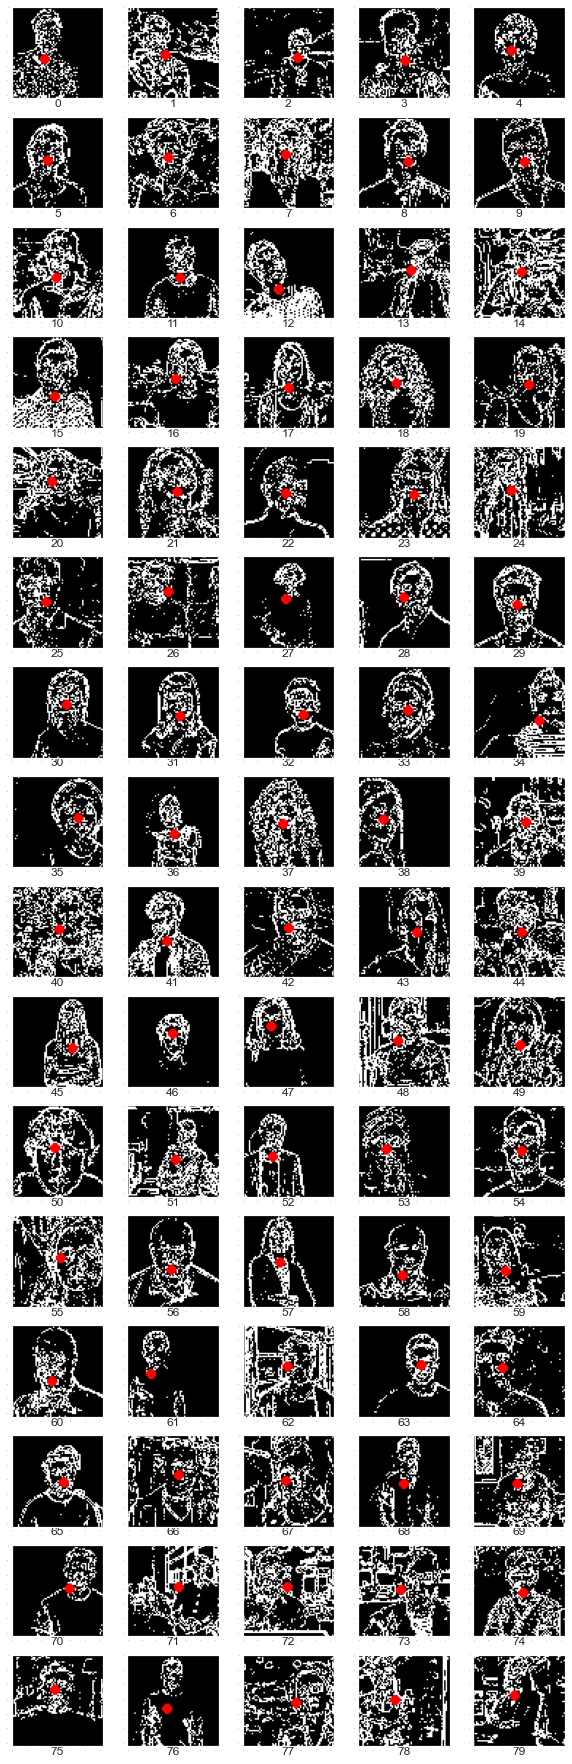

In [74]:
image_grid([place_barycentre(superieur_couleur(img), 3) for img in contour])

In [40]:
contourImage = pd.Series([Image.fromarray(np.array(c)) for c in contour])

In [41]:
def line(img : Image.Image, pA : tuple, pB : tuple) -> Image.Image:
    img = ImageDraw.Draw(img)
    return img.line([pA, pB])

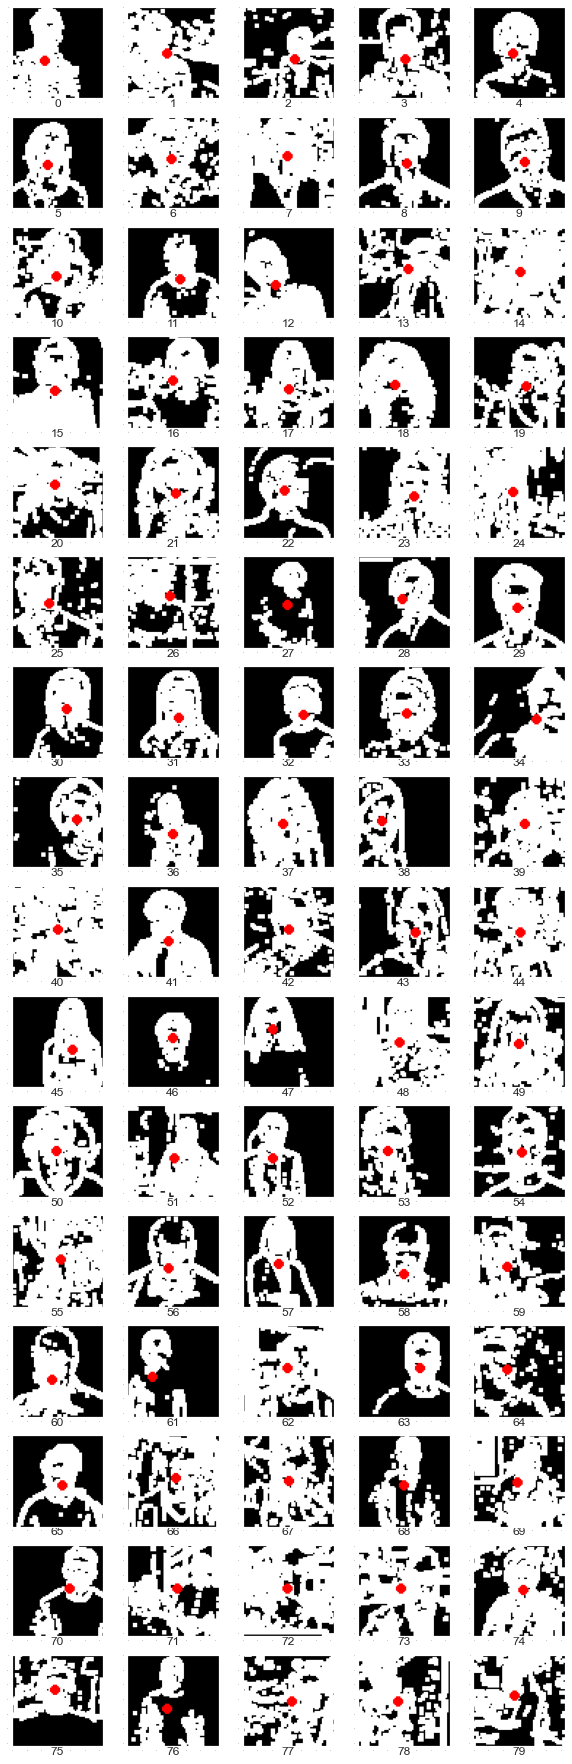

In [75]:
sigma=0.5

from scipy.ndimage import gaussian_filter
img_no_artefacts = [place_barycentre(np.array(gaussian_filter(c,  sigma=sigma)) > 0.1, 3) for c in contourImage]
image_grid(img_no_artefacts)
#On peut considerer ça comme notre "foreground filter"

In [ ]:
for ind, i in enumerate(contourImage):
    b = barycentre(np.array(contour[ind])
    for x in range(i.width):
        for y in range(i.height):
            r,g,b = irgb_im.getpixel((x, y))
            if r == g == b == 255:
                line((i, (x,y), b)

Nous allons utiliser un réseau pré-entraîné appelé `MobileNet`, dont
l'architecture a été optimisé pour fonctionner sur les téléphones
portables. Il a été pré-entraîné pour reconnaître mille catégories
différentes (dont des animaux, des objets de la vie courante etc.).

Depuis la librairie `keras`, importons le modèle pré-entraîné sur la
base de donnée `imagenet` :

In [49]:
import tensorflow as tf
tf.config.run_functions_eagerly(True)

mobilenet = tf.keras.applications.MobileNet(include_top=False, weights='imagenet', input_shape = (64,64,3))

Observons l'architecture en couches de ce réseau de neurones; chaque
ligne ci-dessous décrit brièvement l'une des couches successives :

In [50]:
mobilenet.summary()

Model: "mobilenet_1.00_224"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 64, 64, 3)]       0         
_________________________________________________________________
conv1 (Conv2D)               (None, 32, 32, 32)        864       
_________________________________________________________________
conv1_bn (BatchNormalization (None, 32, 32, 32)        128       
_________________________________________________________________
conv1_relu (ReLU)            (None, 32, 32, 32)        0         
_________________________________________________________________
conv_dw_1 (DepthwiseConv2D)  (None, 32, 32, 32)        288       
_________________________________________________________________
conv_dw_1_bn (BatchNormaliza (None, 32, 32, 32)        128       
_________________________________________________________________
conv_dw_1_relu (ReLU)        (None, 32, 32, 32) 

En déclarant le réseau avec le paramètre `include_top=False`, on a
retiré la dernière couche de neurone. **Le transfert d'apprentissage
va pouvoir être fait en ajoutant des nouvelles couches de neurones
entraînables à la fin de ce réseau pré-entraîné (dont les paramètres
vont être gelés).** Ainsi, on pourra entraîner seulement les dernières
couches de notre réseau sans avoir à réentraîner tout le réseau, ce
qui nécessiterait autrement une puissante carte graphique. En d'autres
termes, le réseau `mobilenet` va nous donner des attributs abstraits
sur lesquels nous allons réentraîner un nouveau réseau de neurones,
plus petit.

On commence par geler les poids du réseau `mobilenet` :

In [51]:
for layer in mobilenet.layers:
    layer.trainable=False

Vérifiez que tous les paramètres de `mobilenet` sont à présent
non-entraînables :

In [52]:
mobilenet.summary()

Model: "mobilenet_1.00_224"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 64, 64, 3)]       0         
_________________________________________________________________
conv1 (Conv2D)               (None, 32, 32, 32)        864       
_________________________________________________________________
conv1_bn (BatchNormalization (None, 32, 32, 32)        128       
_________________________________________________________________
conv1_relu (ReLU)            (None, 32, 32, 32)        0         
_________________________________________________________________
conv_dw_1 (DepthwiseConv2D)  (None, 32, 32, 32)        288       
_________________________________________________________________
conv_dw_1_bn (BatchNormaliza (None, 32, 32, 32)        128       
_________________________________________________________________
conv_dw_1_relu (ReLU)        (None, 32, 32, 32) 

On va à présent ajouter de nouvelles couches entraînables de neurones :

In [53]:
from tensorflow import keras
from keras.models import Model
from keras.layers import Dense,GlobalAveragePooling2D

myneuralnet = keras.Sequential(
    [
        mobilenet,
        GlobalAveragePooling2D(),
        Dense(64, activation="relu", name="layer1"),
        Dense(64, activation="relu", name="layer2"),
        Dense(2, activation="softmax",name="layer3"),
    ]
)

Configurons le réseau `mobilenet` pour prendre en entrée des images de
taille `(32,32,3)`:

In [54]:
myneuralnet.build((None,64,64,3))
myneuralnet.summary()

Model: "sequential_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
mobilenet_1.00_224 (Function (None, 2, 2, 1024)        3228864   
_________________________________________________________________
global_average_pooling2d_2 ( (None, 1024)              0         
_________________________________________________________________
layer1 (Dense)               (None, 64)                65600     
_________________________________________________________________
layer2 (Dense)               (None, 64)                4160      
_________________________________________________________________
layer3 (Dense)               (None, 2)                 130       
Total params: 3,298,754
Trainable params: 69,890
Non-trainable params: 3,228,864
_________________________________________________________________


**Exercice**: À présent combien ce réseau a-t-il de paramètres? Parmi
ces paramètres, combien sont entraînables?

VOTRE RÉPONSE ICI

Chargeons nos données recentrées et recadrées de taille 32x32 :

In [55]:
df_clean = images_resize.apply(image_to_series)
df_clean["class"] = df_clean.index.map(lambda name: 1 if name[0] == 'a' else -1)
df_clean.to_csv('clean_data.csv')

In [56]:
df_clean = pd.read_csv('clean_data.csv', index_col=0)  # chargement du fichier dans le notebook
df_clean

,0,1,2,3,4,5,6,7,8,9,...,12279,12280,12281,12282,12283,12284,12285,12286,12287,class
a1.jpg,92,101,110,94,103,112,95,104,113,94,...,103,112,119,104,113,120,106,115,122,1
a10.jpg,224,198,173,226,195,171,225,194,166,221,...,174,176,175,172,174,173,169,171,170,1
a11.jpg,246,230,214,250,237,221,251,240,228,250,...,145,115,97,158,133,111,155,131,110,1
a12.jpg,206,197,192,206,197,192,207,198,193,208,...,217,202,197,74,65,56,35,31,20,1
a13.jpg,0,209,89,0,209,89,0,208,88,1,...,2,206,85,2,206,85,2,206,85,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
b5.jpg,75,58,42,88,70,51,99,81,56,91,...,1,28,46,2,28,43,6,20,18,-1
b6.jpg,231,183,37,233,185,39,234,187,40,236,...,233,186,54,232,185,53,230,183,51,-1
b7.jpg,21,6,1,22,8,3,60,42,25,93,...,34,60,75,12,22,31,2,6,11,-1
b8.jpg,173,167,126,161,157,122,185,186,158,187,...,217,230,236,213,231,235,211,230,234,-1


On souhaite avoir une variable `X` de type `np.ndarray` de taille
`(491, 32, 32, 3)` c'est à dire `(nombre d'images, largeur, hauteur,
nombre de couches de couleurs)` :

In [57]:
X = np.array(df_clean.drop(['class'], axis=1)).reshape((80, 64, 64, 3))

Il est nécessaire d'encoder les étiquettes sous la forme d'un *one-hot
vector* c'est-à-dire d'un tableau `y_onehot` de taille `(nombre
d'images, nombre de classes)` tel que `y_onehot[i,j]==1` si la i-ème
étiquette est la j-ème classe et `0` sinon. Dans notre cas, la i-ème
ligne vaut `(1,0)` si le i-ème fruit est une pomme, et `(0,1)` si
c'est une banane :

In [58]:
y = np.array(df_clean["class"])
classes = np.unique(y)
class_to_class_number = { cls: number for number, cls in enumerate(classes) }
y_onehot = np.zeros((len(y), len(np.unique(y))))
for i, label in enumerate(y):
    y_onehot[i, class_to_class_number[label]] = 1

On doit maintenant définir l'***optimisateur*** et la ***fonction de
coût*** qui vont permettre d'optimiser les paramètres de nos
neurones. Les poids des neurones vont être optimisés pour ***minimiser
la fonction de coût*** (*loss*) :

In [59]:
opt = keras.optimizers.Adam(learning_rate=0.01)
myneuralnet.compile(loss='categorical_crossentropy', metrics=["accuracy"], optimizer=opt)

Avant de pouvoir entraîner notre réseau, on va d'abord diviser nos
données en deux: les données d'entraînement et les données de test :

In [60]:
test = np.array(y == 1, dtype = int)
X_train = np.concatenate((X[:165], X[333:333+ 79]), axis = 0)
y_train = np.concatenate((y_onehot[:165], y_onehot[333:333+ 79]), axis = 0)

X_test = np.concatenate((X[165:333], X[333+ 79:]), axis = 0)
y_test = np.concatenate((y_onehot[165:333], y_onehot[333+ 79:]), axis = 0)

On peut finalement entraîner notre réseau de neurone !  

**Attention :** Le temps de calcul étant potentiellement élevé, la
cellule ci-dessous est désactivée par défaut. Mettez en commentaire la
première ligne pour lancer le calcul.

In [77]:


from sklearn.model_selection import StratifiedKFold
import pdb
stop = pdb.set_trace
def create_model():
    myneuralnet = keras.Sequential(
    [
        mobilenet,
        GlobalAveragePooling2D(),
        Dense(64, activation="relu", name=f"layer1"),
        Dense(64, activation="relu", name=f"layer2"),
        Dense(64, activation="relu", name=f"layer3"),
        Dense(64, activation="relu", name=f"layer4"),
        Dense(2, activation="softmax",name=f"layer5"),
    ])
    myneuralnet.build((None,64,64,3))
    opt = keras.optimizers.Adam(learning_rate=0.01)
    myneuralnet.compile(loss='categorical_crossentropy', metrics=["accuracy"], optimizer=opt)
    return myneuralnet

def train_evaluate(model, x_train, y_train, x_test, y_test):
    history = model.fit(x_train, y_train, epochs = 13, shuffle = True)
    return model.evaluate(x_test, y_test)

kFold = StratifiedKFold(n_splits=30)
scores = np.zeros(30)
idx = 0
for train, test in kFold.split(X, y):
    model = create_model()
    scores[idx] = train_evaluate(model, X[train], y_onehot[train], X[test], y_onehot[test])[1]
    idx += 1
print(scores)
print(scores.mean())

Epoch 1/13
3/3 [==============================] - 1s 179ms/step - loss: 1.3783 - accuracy: 0.5189
Epoch 2/13
3/3 [==============================] - 1s 171ms/step - loss: 1.3235 - accuracy: 0.5136
Epoch 3/13
3/3 [==============================] - 1s 170ms/step - loss: 0.8099 - accuracy: 0.4968
Epoch 4/13
3/3 [==============================] - 1s 178ms/step - loss: 0.6710 - accuracy: 0.5358
Epoch 5/13
3/3 [==============================] - 1s 179ms/step - loss: 0.6657 - accuracy: 0.5215
Epoch 6/13
3/3 [==============================] - 1s 177ms/step - loss: 0.6184 - accuracy: 0.6554
Epoch 7/13
3/3 [==============================] - 1s 175ms/step - loss: 0.6152 - accuracy: 0.7244
Epoch 8/13
3/3 [==============================] - 1s 177ms/step - loss: 0.6392 - accuracy: 0.6203
Epoch 9/13
3/3 [==============================] - 1s 173ms/step - loss: 0.6213 - accuracy: 0.6072
Epoch 10/13
3/3 [==============================] - 1s 179ms/step - loss: 0.4920 - accuracy: 0.7932
Epoch 11/13
3/3 [==

3/3 [==============================] - 1s 174ms/step - loss: 1.2287 - accuracy: 0.5423
Epoch 2/13
3/3 [==============================] - 1s 179ms/step - loss: 0.7481 - accuracy: 0.5319
Epoch 3/13
3/3 [==============================] - 1s 177ms/step - loss: 0.7225 - accuracy: 0.5592
Epoch 4/13
3/3 [==============================] - 1s 176ms/step - loss: 0.7717 - accuracy: 0.5449
Epoch 5/13
3/3 [==============================] - 1s 172ms/step - loss: 0.6781 - accuracy: 0.4760
Epoch 6/13
3/3 [==============================] - 1s 174ms/step - loss: 0.5857 - accuracy: 0.6606
Epoch 7/13
3/3 [==============================] - 1s 175ms/step - loss: 0.5512 - accuracy: 0.7204
Epoch 8/13
3/3 [==============================] - 1s 180ms/step - loss: 0.4450 - accuracy: 0.7867
Epoch 9/13
3/3 [==============================] - 1s 183ms/step - loss: 0.4141 - accuracy: 0.7620
Epoch 10/13
3/3 [==============================] - 1s 180ms/step - loss: 0.3449 - accuracy: 0.8309
Epoch 11/13
3/3 [=============

3/3 [==============================] - 1s 174ms/step - loss: 0.7820 - accuracy: 0.4616
Epoch 2/13
3/3 [==============================] - 1s 178ms/step - loss: 2.4761 - accuracy: 0.5566
Epoch 3/13
3/3 [==============================] - 1s 171ms/step - loss: 0.7259 - accuracy: 0.5462
Epoch 4/13
3/3 [==============================] - 1s 178ms/step - loss: 0.7537 - accuracy: 0.5228
Epoch 5/13
3/3 [==============================] - 1s 171ms/step - loss: 0.6701 - accuracy: 0.6867
Epoch 6/13
3/3 [==============================] - 1s 173ms/step - loss: 0.6449 - accuracy: 0.5735
Epoch 7/13
3/3 [==============================] - 1s 171ms/step - loss: 0.6071 - accuracy: 0.6502
Epoch 8/13
3/3 [==============================] - 1s 175ms/step - loss: 0.6249 - accuracy: 0.6463
Epoch 9/13
3/3 [==============================] - 1s 172ms/step - loss: 0.5016 - accuracy: 0.7789
Epoch 10/13
3/3 [==============================] - 1s 174ms/step - loss: 0.4232 - accuracy: 0.8179
Epoch 11/13
3/3 [=============

Afficher les valeurs d'accuracy au fur et à mesure des itérations
d'optimisations :

Text(0, 0.5, 'Accuracy')

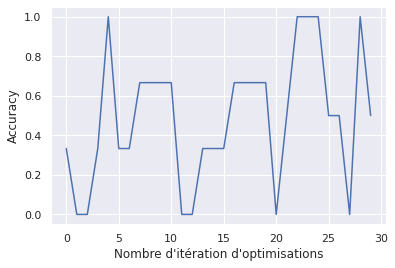

In [78]:


plt.plot(scores)
plt.xlabel("Nombre d'itération d'optimisations")
plt.ylabel("Accuracy")